In [1]:
a = 10

d:\DIGIT_IDENTIFICATION\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\DIGIT_IDENTIFICATION\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Saranya\.cache\huggingface\hub\datasets--tanganke--emnist_letters. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mo

Training samples: 124800
Testing samples: 20800


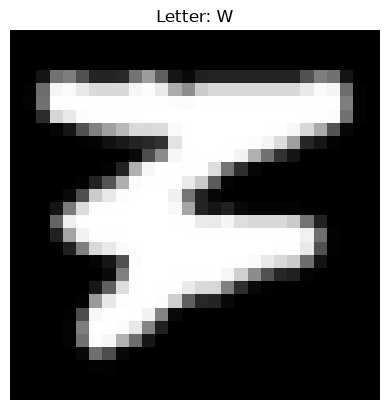

In [3]:
from datasets import load_dataset
import matplotlib.pyplot as plt

# Load EMNIST Letters
dataset = load_dataset("tanganke/emnist_letters")

# Separate training and testing data
train_data = dataset["train"]
test_data = dataset["test"]

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

# Display one handwritten letter
sample = train_data[0]

plt.imshow(sample["image"], cmap="gray")
label = train_data.features["label"].int2str(sample["label"])
plt.title(f"Letter: {label}")
plt.axis("off")
plt.show()

In [19]:
sample["image"]

In [20]:
import numpy as np

image_array = np.array(sample["image"].convert("L"))

print(image_array)

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   1   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0  20 114 125  82  37  37  39 115 157  94  21  10  32  37  37  37
   37  37  37  37  82 125 114  20   0   0]
 [  0   3 109 245 249 233 217 217 217 245 251 234 172 142 203 217 217 217
  217 217 217 217 233 249 245 109   3   0]
 [  0   4 114 253 254 254 254 254 254 254 254 254 252 251 254 254 254 254
  254 254 254 254 254 254 254 127   4   0]
 [  0   0  45 214 233 251 254 254 254 254 255 255 255 255 255 255 255 255
  255 255 255 255 254 254 251 113   4   0]
 [  0   0   0   5  22  82 128 160 184 217 217 218 249 254 255 255 255 255
  255 254 254 247 216 170  83   7   0   0]
 [  0   0   0   0   0   2   5  16  25  37  40  50 227 254 255 25

In [23]:
train_data[0]

{'image': <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28>,
 'label': 22}

In [24]:
print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

Training samples: 124800
Testing samples: 20800


In [25]:
import numpy as np

# Convert images to grayscale arrays
X_train = np.array([
    np.array(img.convert("L"))
    for img in train_data["image"]
])

X_test = np.array([
    np.array(img.convert("L"))
    for img in test_data["image"]
])

y_train = np.array(train_data["label"])
y_test = np.array(test_data["label"])

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (124800, 28, 28)
Testing data: (20800, 28, 28)


In [26]:
# Flatten images: 28 × 28 → 784
X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (124800, 784)
Testing shape: (20800, 784)


In [27]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

model = Sequential([
    Input(shape=(784,)),
    Dense(256, activation="relu"),
    Dense(128, activation="relu"),
    Dense(26, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 237,210 (926.60 KB)

 Trainable params: 237,210 (926.60 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
[[150, 60, 23, 20000], [150, 60, 23, 20000],............]

In [ ]:
[[[.....],[......]], [[.......],[........]]]

In [ ]:
(28,28)

In [ ]:
[1,2,3............,784],[1,2,.........,784]

In [28]:
import numpy as np

# Convert images into arrays
X_train = np.array([
    np.array(img.convert("L")) for img in train_data["image"]
])

X_test = np.array([
    np.array(img.convert("L")) for img in test_data["image"]
])

y_train = np.array(train_data["label"])
y_test = np.array(test_data["label"])

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)
print("Label range:", y_train.min(), y_train.max())

Training samples: (124800, 28, 28)
Testing samples: (20800, 28, 28)
Label range: 0 25


In [29]:
# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Convert labels from 1–26 to 0–25, if needed
if y_train.min() == 1:
    y_train = y_train - 1
    y_test = y_test - 1

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (124800, 28, 28, 1)
X_test: (20800, 28, 28, 1)


In [32]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)

model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(26, activation="softmax")
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 227,098 (887.10 KB)

 Trainable params: 227,098 (887.10 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [34]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
878/878 ━━━━━━━━━━━━━━━━━━━━ 19s 20ms/step - accuracy: 0.7818 - loss: 0.7069 - val_accuracy: 0.9018 - val_loss: 0.3016
Epoch 2/10
878/878 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.8863 - loss: 0.3557 - val_accuracy: 0.9193 - val_loss: 0.2540
Epoch 3/10
878/878 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.9039 - loss: 0.2933 - val_accuracy: 0.9256 - val_loss: 0.2252
Epoch 4/10
878/878 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.9153 - loss: 0.2585 - val_accuracy: 0.9317 - val_loss: 0.2084
Epoch 5/10
878/878 ━━━━━━━━━━━━━━━━━━━━ 23s 26ms/step - accuracy: 0.9218 - loss: 0.2338 - val_accuracy: 0.9319 - val_loss: 0.1989
Epoch 6/10
878/878 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - accuracy: 0.9272 - loss: 0.2145 - val_accuracy: 0.9350 - val_loss: 0.1914
Epoch 7/10
878/878 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - accuracy: 0.9325 - loss: 0.1971 - val_accuracy: 0.9386 - val_loss: 0.1892
Epoch 8/10
878/878 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.9368 - loss: 0.1841 - 

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.show()

In [ ]:
index = 0

prediction = model.predict(X_test[index:index+1], verbose=0)
predicted_label = np.argmax(prediction)

plt.imshow(X_test[index].squeeze(), cmap="gray")
plt.title(f"Predicted Letter: {chr(predicted_label + 65)}")
plt.axis("off")
plt.show()

In [35]:
# Save the trained CNN model
model.save("emnist_cnn_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [36]:
from tensorflow.keras.models import load_model

# Load the saved model
model = load_model("emnist_cnn_model.keras")

print("Model loaded successfully!")

Model loaded successfully!


In [37]:
import numpy as np

# Select an image
image = X_test[0]

# Predict the letter
prediction = model.predict(image.reshape(1, 28, 28, 1))
predicted_label = np.argmax(prediction)

print("Predicted letter:", chr(predicted_label + 65))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
Predicted letter: A


In [ ]:
X_test[0]